### Ivan Frolov 
#### Home Assignment 2

---

#### Pre-requisite

I created 2 accounts directly in MetaMask.  

address_1 = "0x666515BBCe9E7Db0F89BA0f767e4A419B166761b".  
address_2 = "0x70dD93dc39DFd2E7bCD073152E98AD6fEfF53036".  

Then put their Private keys in .env 

In [11]:
import os
from pathlib import Path
from dotenv import load_dotenv
from web3 import Web3

env_path = Path.cwd() / ".env"
if not env_path.exists():
    raise FileNotFoundError(f"Could not find .env at {env_path}")
load_dotenv(dotenv_path=env_path, override=True)

INFURA_PROJECT_ID = os.getenv("INFURA_PROJECT_ID")
PRIVATE_KEY_1 = (os.getenv("PRIVATE_KEY_1") or "").strip()
PRIVATE_KEY_2 = (os.getenv("PRIVATE_KEY_2") or "").strip()

if not INFURA_PROJECT_ID:
    raise ValueError("INFURA_PROJECT_ID is missing from .env")

# The private keys are loaded for later transactions but are never printed.
if not PRIVATE_KEY_1 or not PRIVATE_KEY_2:
    raise ValueError(f"PRIVATE_KEY_1 and PRIVATE_KEY_2 must be set in {env_path}")

address_1 = Web3.to_checksum_address("0x666515BBCe9E7Db0F89BA0f767e4A419B166761b")
address_2 = Web3.to_checksum_address("0x70dD93dc39DFd2E7bCD073152E98AD6fEfF53036")

print("Address 1:", address_1)
print("Address 2:", address_2)

Address 1: 0x666515BBCe9E7Db0F89BA0f767e4A419B166761b
Address 2: 0x70dD93dc39DFd2E7bCD073152E98AD6fEfF53036


#### Task 1 (1 point) 
Create a user-interacting interface to connect to different blockchain networks, i.e., mainnet, testnets (any two), and ganache 

(Hint: Take input from the User and use the if-else method to connect to different networks. User different Infura/Alchemy Endpoints). 

In [5]:
def connect_to_network(network):
    network = network.strip().lower()

    mainnet_url = f"https://mainnet.infura.io/v3/{INFURA_PROJECT_ID}"
    sepolia_url = f"https://sepolia.infura.io/v3/{INFURA_PROJECT_ID}"
    hoodi_url = f"https://hoodi.infura.io/v3/{INFURA_PROJECT_ID}"
    ganache_url = "http://127.0.0.1:7545"

    if network == "mainnet":
        rpc_url = mainnet_url
        network_name = "Ethereum Mainnet"
    elif network == "sepolia":
        rpc_url = sepolia_url
        network_name = "Sepolia Testnet"
    elif network == "hoodi":
        rpc_url = hoodi_url
        network_name = "Hoodi Testnet"
    elif network == "ganache":
        rpc_url = ganache_url
        network_name = "Ganache"
    else:
        raise ValueError(f"Error: {network}")

    web3 = Web3(Web3.HTTPProvider(rpc_url, request_kwargs={"timeout": 10}))

    if web3.is_connected():
        print("Connected successfully")
        print("Network:", network_name)
        print("Chain ID:", web3.eth.chain_id)
        print("Latest block:", web3.eth.block_number)
    else:
        print("Connection failed:", network_name)

    print("-" * 40)
    return web3 if web3.is_connected() else None

In [6]:
# Check connections

networks = ["mainnet", "sepolia", "hoodi", "ganache"]
connections = {}

for network in networks:
    try:
        connections[network] = connect_to_network(network)
    except Exception as error:
        connections[network] = None
        print(f"{network}: {error}")
        print("-" * 40)

Connected successfully
Network: Ethereum Mainnet
Chain ID: 1
Latest block: 26161255
----------------------------------------
Connected successfully
Network: Sepolia Testnet
Chain ID: 11155111
Latest block: 11883753
----------------------------------------
Connected successfully
Network: Hoodi Testnet
Chain ID: 560048
Latest block: 3788559
----------------------------------------
Connected successfully
Network: Ganache
Chain ID: 1337
Latest block: 0
----------------------------------------


Some random accounts from local Ganache (just to show it was running): 

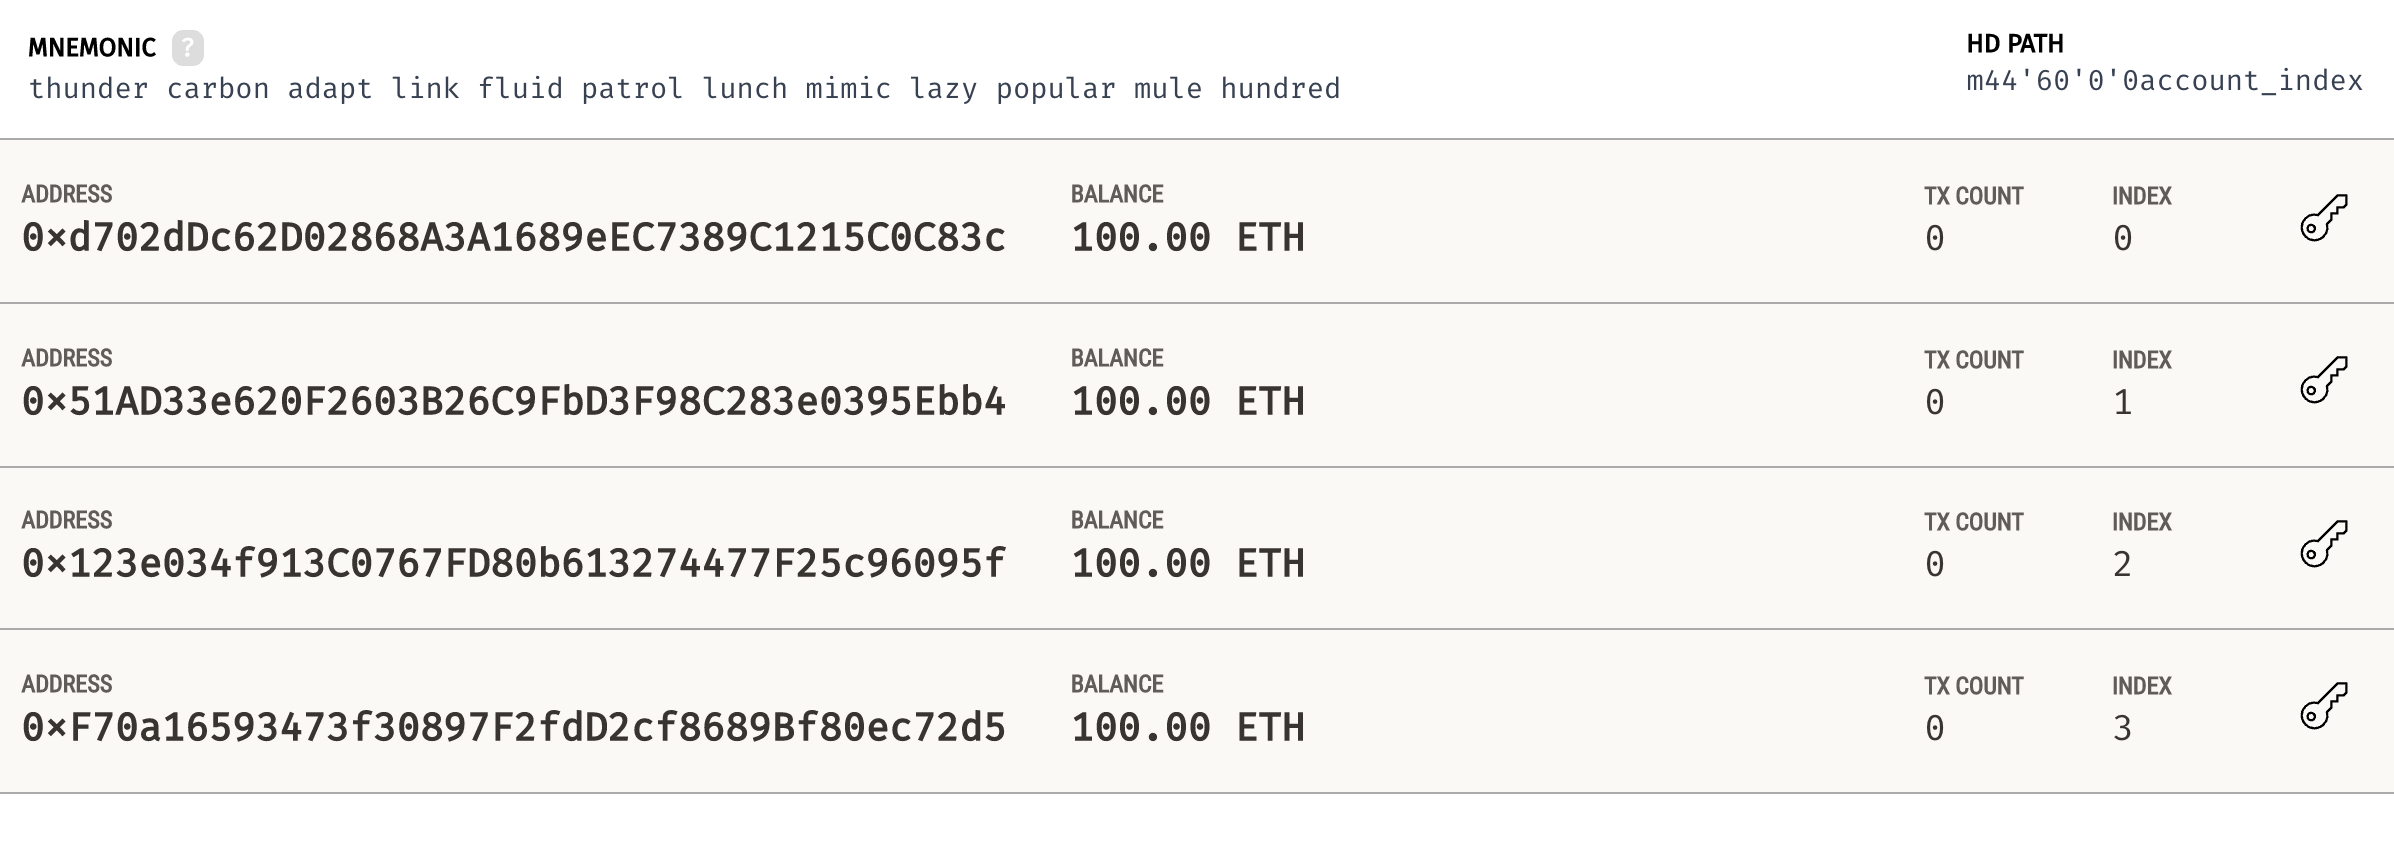

#### Task 2 (1 point) 
Get some Ethereum test coins for your testnet address_1 from any faucet. Provide the transaction link for the testnet work. 

Faucet Sources:
- Sepolia: https://cloud.google.com/application/web3/faucet/ethereum/sepolia    
- Sepolia: https://faucets.chain.link/ (Note: Select Drip 0.1 ETH).  
- BNB: https://discord.com/invite/bnbchain    

In [7]:
sepolia_faucet_transaction = "0x26fbceae7e91d216bc620953b20f5250ea179054442816a6314f6580b240baee"
print(f"https://sepolia.etherscan.io/tx/{sepolia_faucet_transaction}")

https://sepolia.etherscan.io/tx/0x26fbceae7e91d216bc620953b20f5250ea179054442816a6314f6580b240baee


#### Task 3 (2 points) 
From Task_1, connect to the Ethereum network and provide codes to interact with the blockchain (Testnet will be better): 

- Checking block height at any time.
- Getting information about a block.
- Get balance information of your address_1.
- From Task 4.3. Convert the balance to ether. (Hint: https://web3js.readthedocs.io/en/v1.2.4/ or https://web3py.readthedocs.io/) 

In [8]:
web3 = connections.get("sepolia") 

latest_block_number = web3.eth.block_number
latest_block = web3.eth.get_block(latest_block_number)
balance_wei = web3.eth.get_balance(address_1)
balance_eth = Web3.from_wei(balance_wei, "ether")

print("Current block height:", latest_block_number)
print("Block hash:", latest_block.hash.hex())
print("Block timestamp:", latest_block.timestamp)
print("Gas limit:", latest_block.gasLimit)
print("Address 1 balance in Wei:", balance_wei)
print("Address 1 balance in ETH:", balance_eth)

Current block height: 11883799
Block hash: 9973d356a3791fc06ea6643ce9810fc73d0b26bcd92412bab87f77dbcab680e1
Block timestamp: 1791626472
Gas limit: 199999809
Address 1 balance in Wei: 50000000000000000
Address 1 balance in ETH: 0.05


#### Task 4 (1 point) 
Send some Eth test coins from address_1 to address_2 and provide Transaction_ID. (Use seminar file, not Metamask) 

In [13]:
amount_eth = 0.001
amount_wei = Web3.to_wei(amount_eth, "ether")
sender_account = web3.eth.account.from_key(PRIVATE_KEY_1)
sender_address = Web3.to_checksum_address(sender_account.address)

if sender_address != address_1:
    raise ValueError("PRIVATE_KEY_1 does not belong to address_1")

nonce = web3.eth.get_transaction_count(sender_address, "pending")
gas_price = web3.eth.gas_price
gas_estimate_transaction = {
    "from": sender_address,
    "to": address_2,
    "value": amount_wei,
} 
# estimating gas amount 
gas_estimate = web3.eth.estimate_gas(gas_estimate_transaction)
gas_limit = int(gas_estimate * 1.20) 

transaction = {
    "nonce": nonce,
    "to": address_2,
    "value": amount_wei,
    "gas": gas_limit,
    "gasPrice": gas_price,
    "chainId": web3.eth.chain_id,
}
signed_transaction = web3.eth.account.sign_transaction(transaction, PRIVATE_KEY_1)
transaction_hash = web3.eth.send_raw_transaction(signed_transaction.raw_transaction)
print("Transaction ID:", transaction_hash.hex())
print(f"https://sepolia.etherscan.io/tx/{transaction_hash.hex()}")

Transaction ID: 67bfb50c96ded6bdf7bc229c2d7a5b425214044c926db2c52f552c4c60ddd650
https://sepolia.etherscan.io/tx/67bfb50c96ded6bdf7bc229c2d7a5b425214044c926db2c52f552c4c60ddd650


It worked :) 

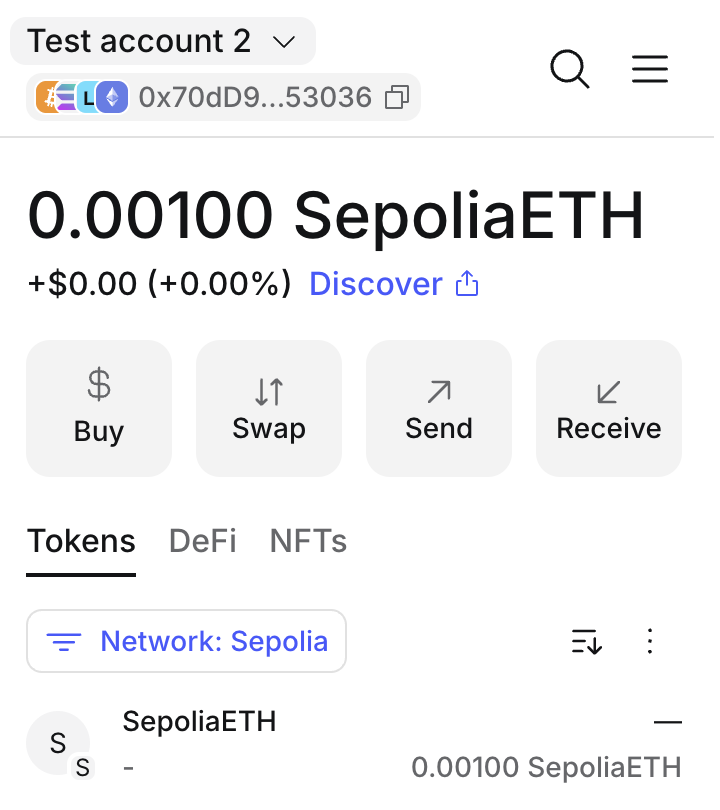 
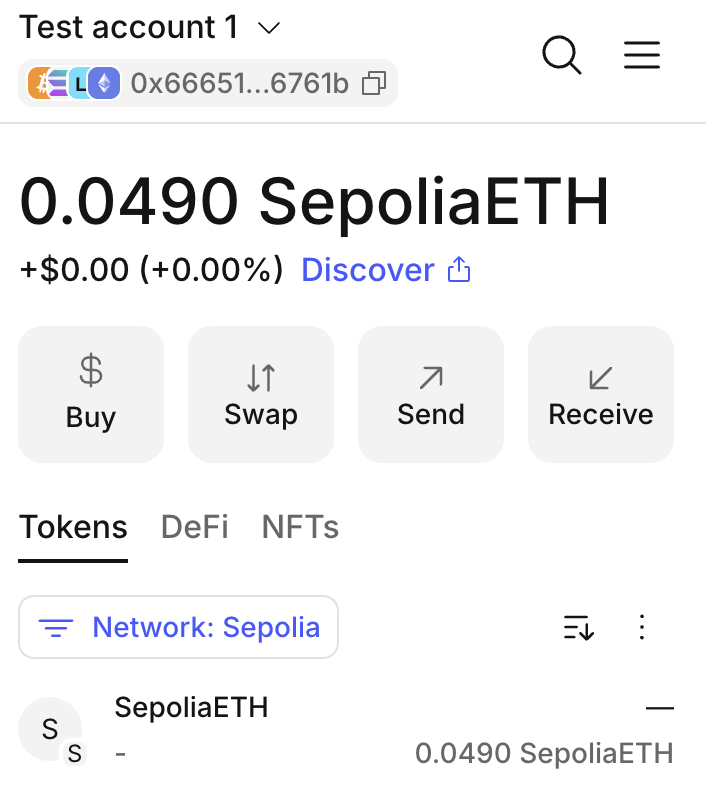 
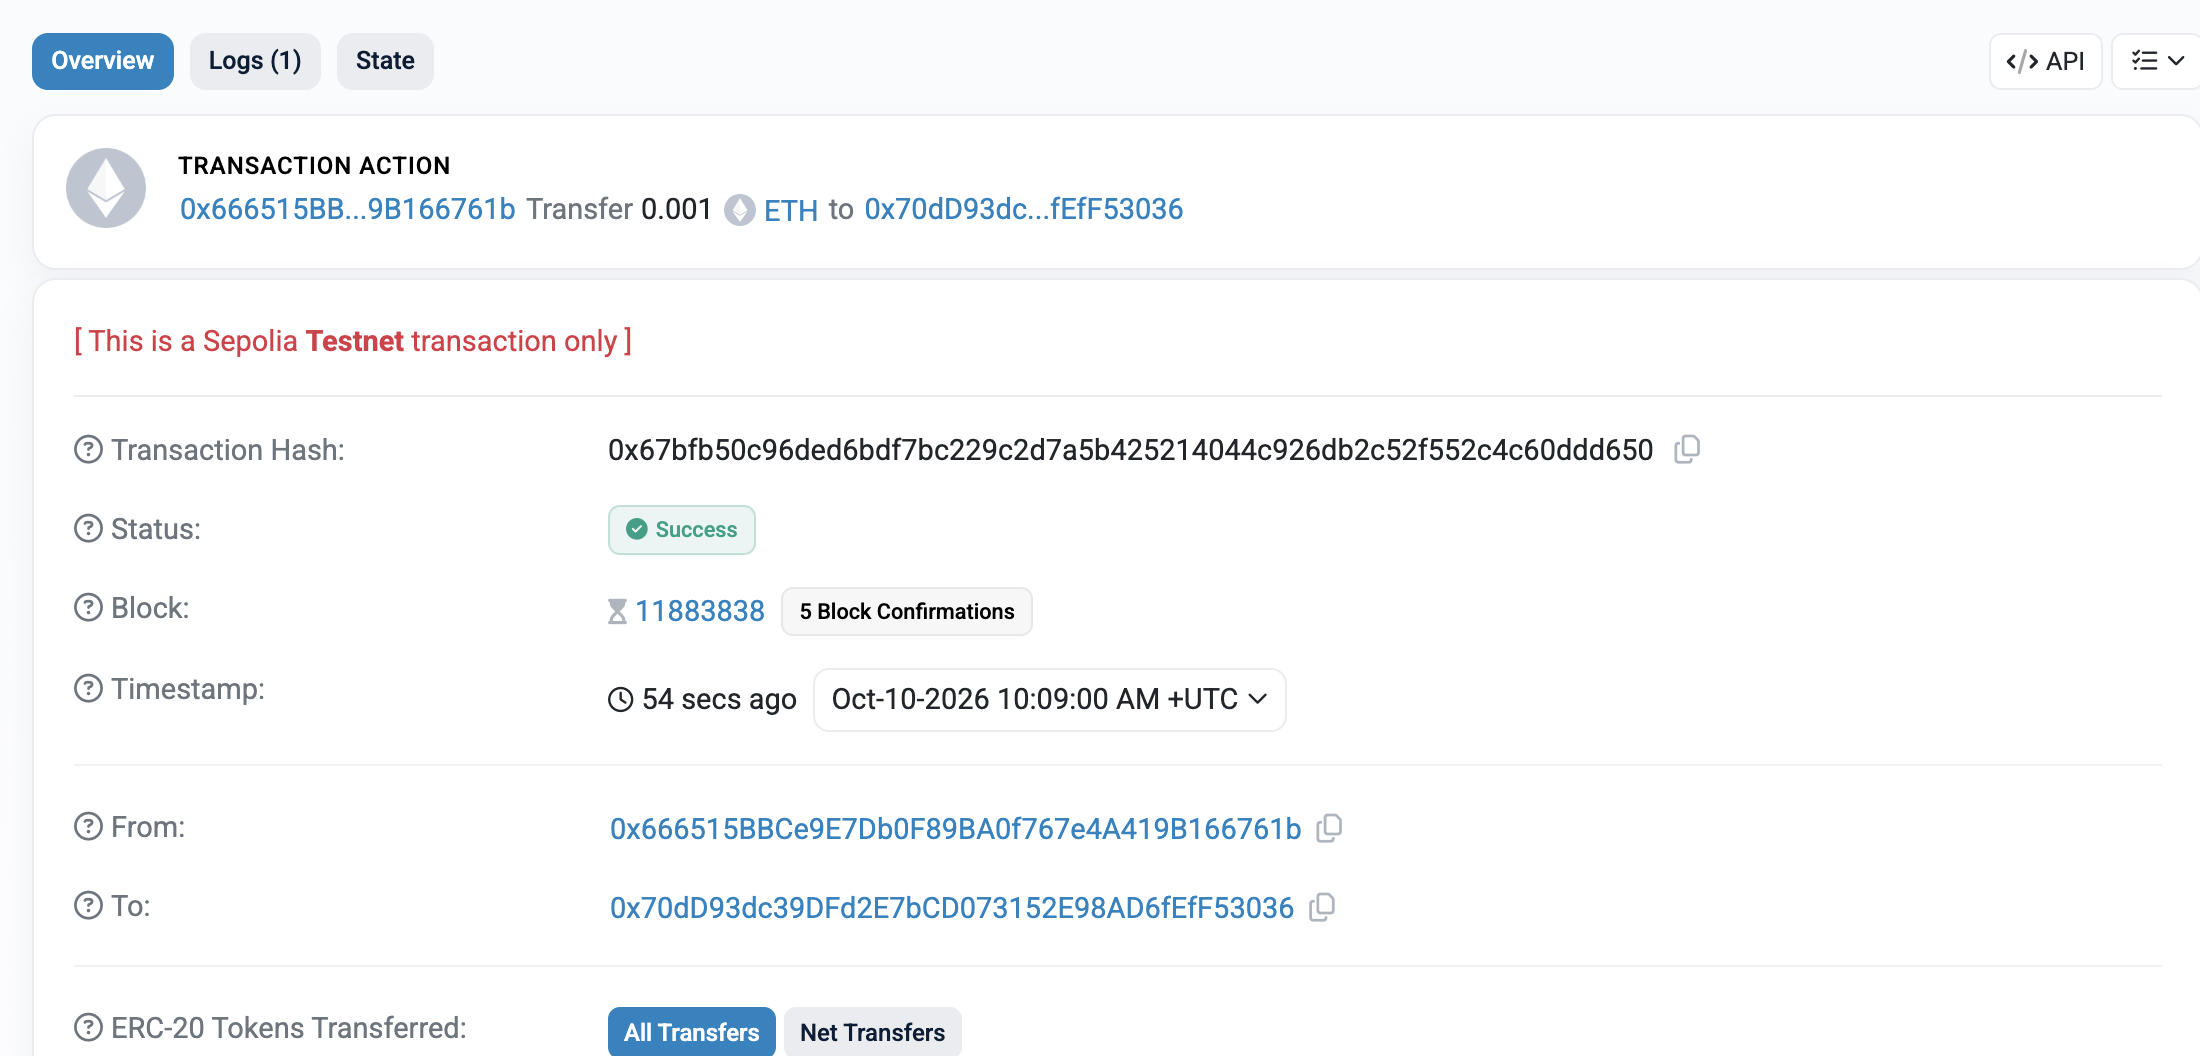 

#### Task 5 (2 points) 

Create a smart contract to add two numbers. (Hint: 
- Use ide http://remix.ethereum.org/.
- Use any version of the compiler.
- Create a function to do different types different arithmetic operations (passing two parameters from User) variables declared in the state variable. Hint: use multiple functions for different operations.
- Connect to any blockchain.
- Just provide the code.
- Reference document: https://docs.soliditylang.org/en/v0.8.28/).

Just provide screenshot/raw code. 

### Solution code

```solidity
// SPDX-License-Identifier: MIT
pragma solidity ^0.8.20;

contract AplusB {
    uint256 public firstNumber;
    uint256 public secondNumber;

    function setNumbers(uint256 _firstNumber, uint256 _secondNumber) public {
        firstNumber = _firstNumber;
        secondNumber = _secondNumber;
    }

    function add() public view returns (uint256) { return firstNumber + secondNumber; }
    function subtract() public view returns (uint256) {
        return firstNumber - secondNumber;
    }
    function multiply() public view returns (uint256) { return firstNumber * secondNumber; }
}
```

3 * 1 = 3

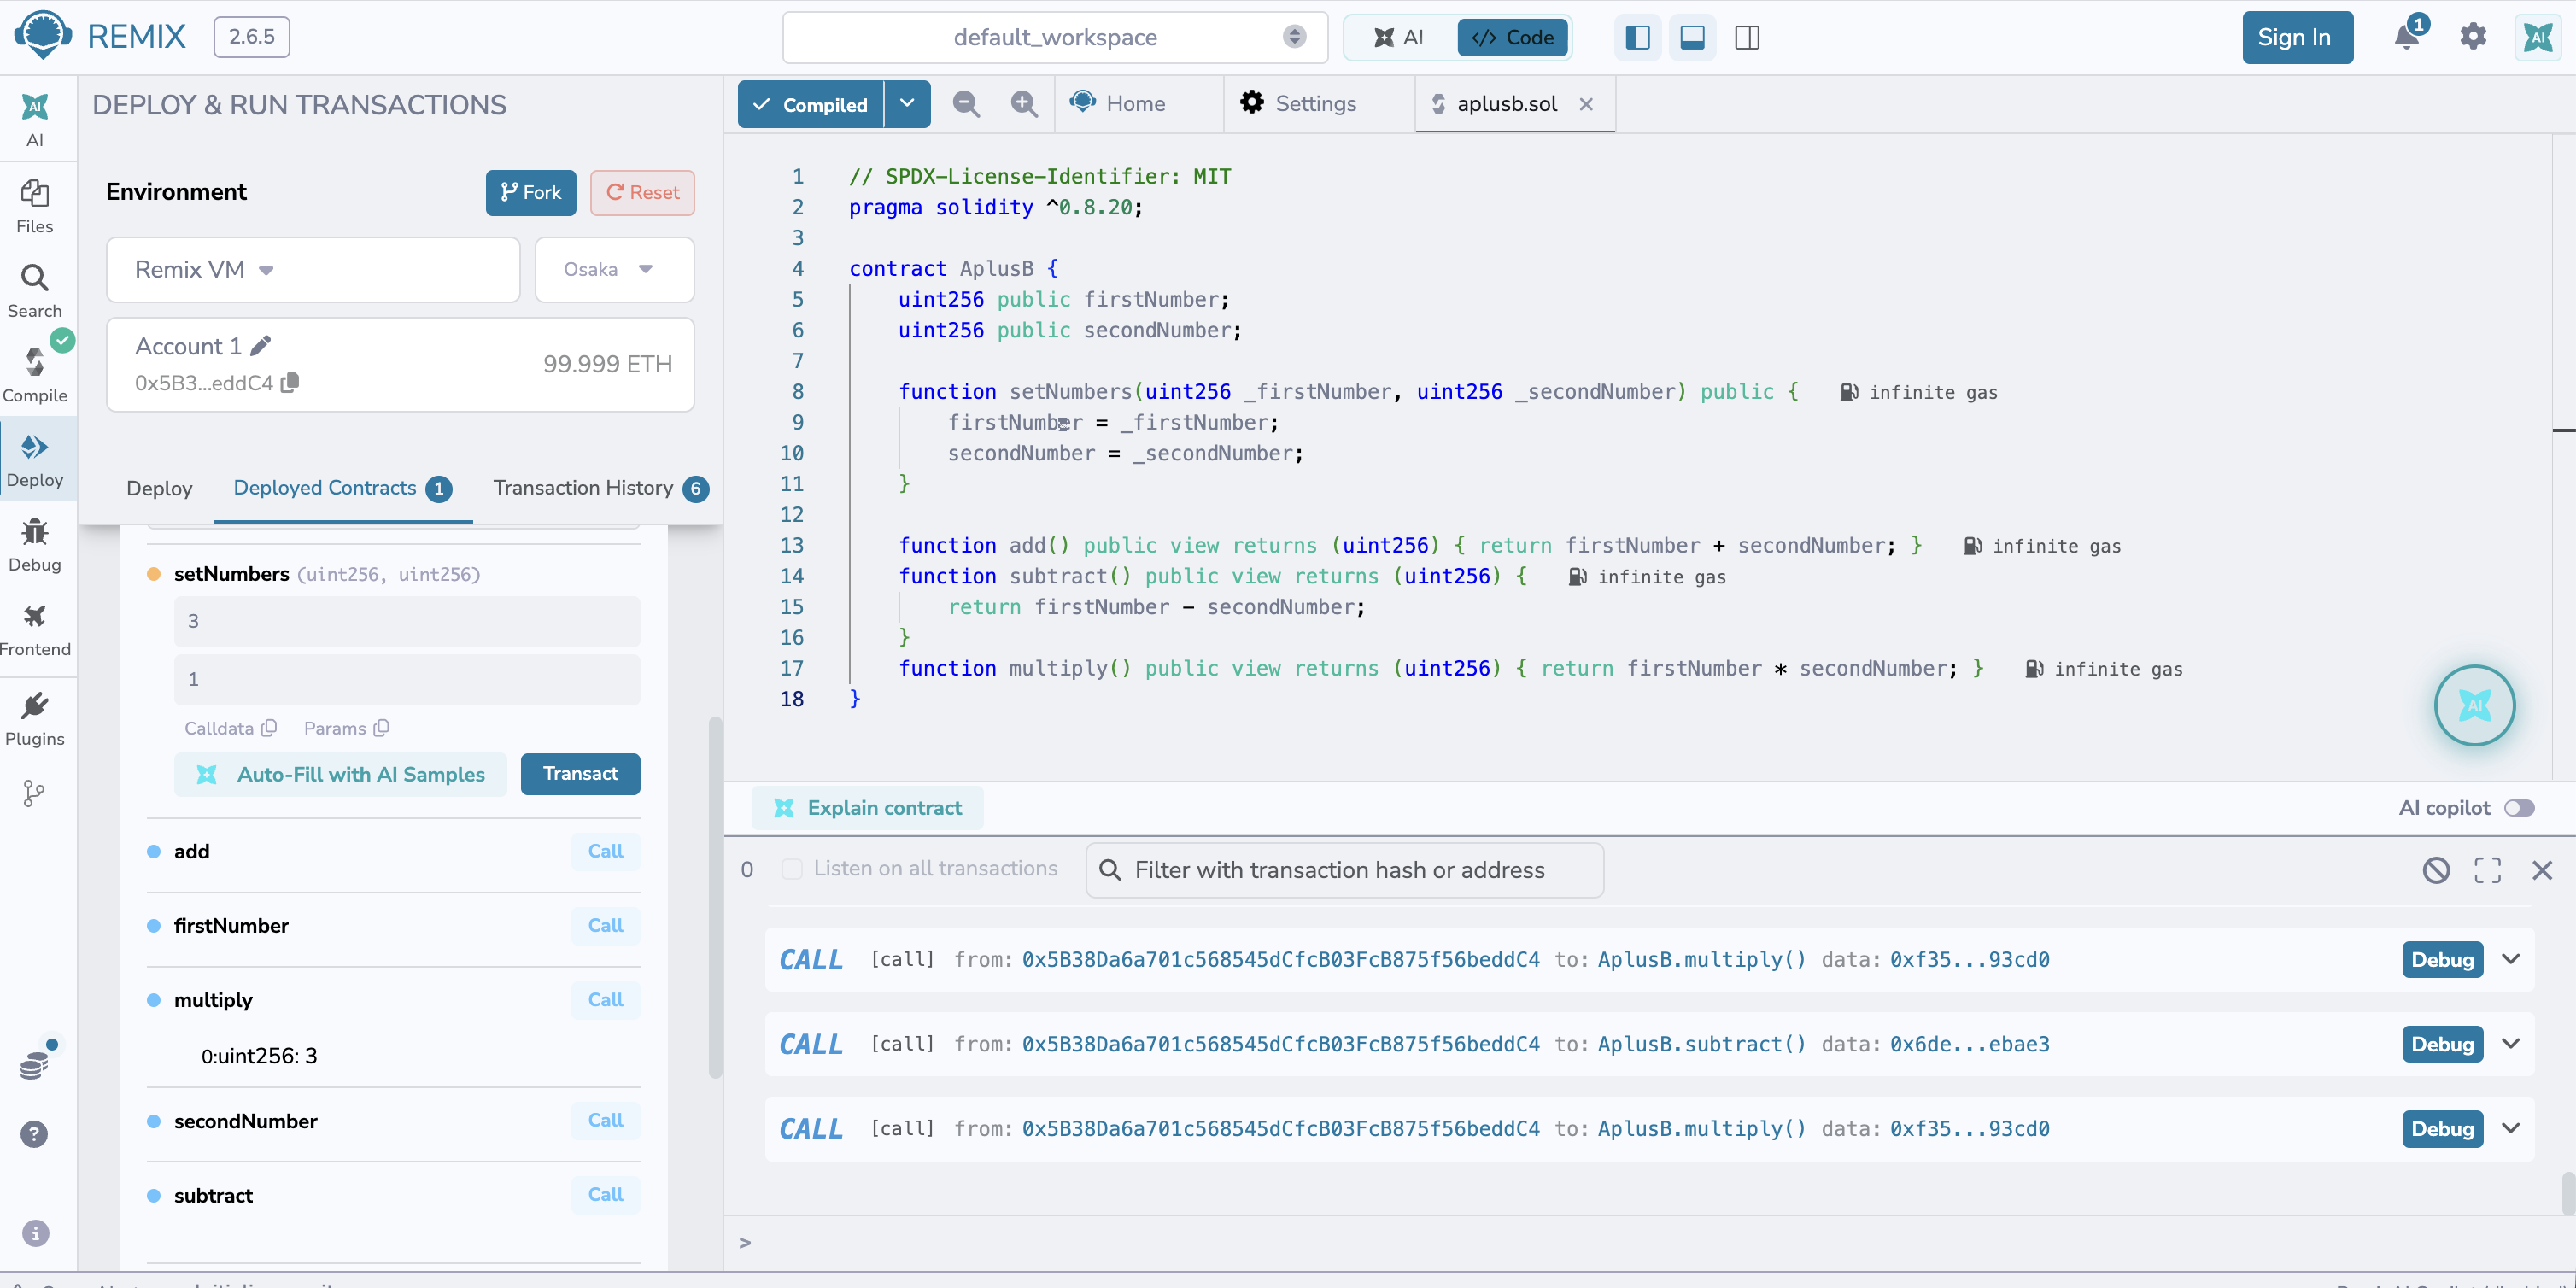

#### Task 6 (3 points) Create an ERC20 smart contract:

- Create 100 tokens.
- Deploy the contract from address_2. Provide contract creation transaction_id and contract address (the address created when the contract is deployed) and a 3-letter abbreviation of your coin. We will check the existence of the token on testnet (anytestnet).
- Send ten tokens to 0x80773c866332a7f3CFdD583d0b3A96655F035d6C address. (Provide Transaction Id)

### Solution code

```solidity
// SPDX-License-Identifier: MIT
pragma solidity ^0.8.20;

import {ERC20} from "@openzeppelin/contracts/token/ERC20/ERC20.sol";

contract CourseworkToken is ERC20 {
    uint256 public constant INITIAL_SUPPLY = 100 * 10 ** 18;

    constructor() ERC20("Ivan Frolov Token", "IFT") {
        _mint(msg.sender, INITIAL_SUPPLY);
    }
}
```

Sending some more tokens to account 2 (so it can deploy the contract) 

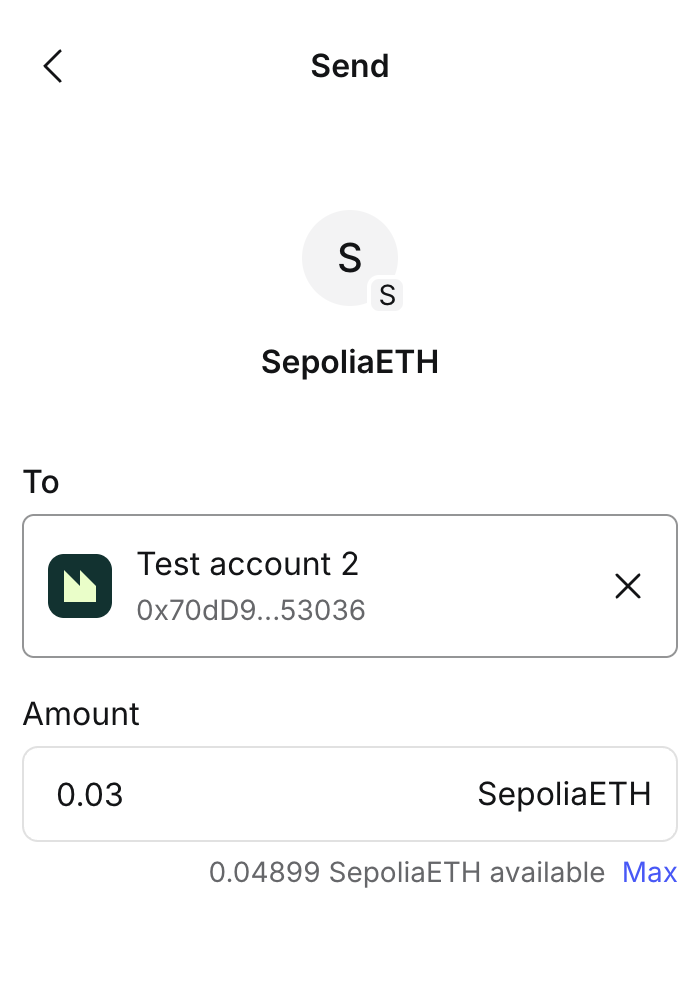 

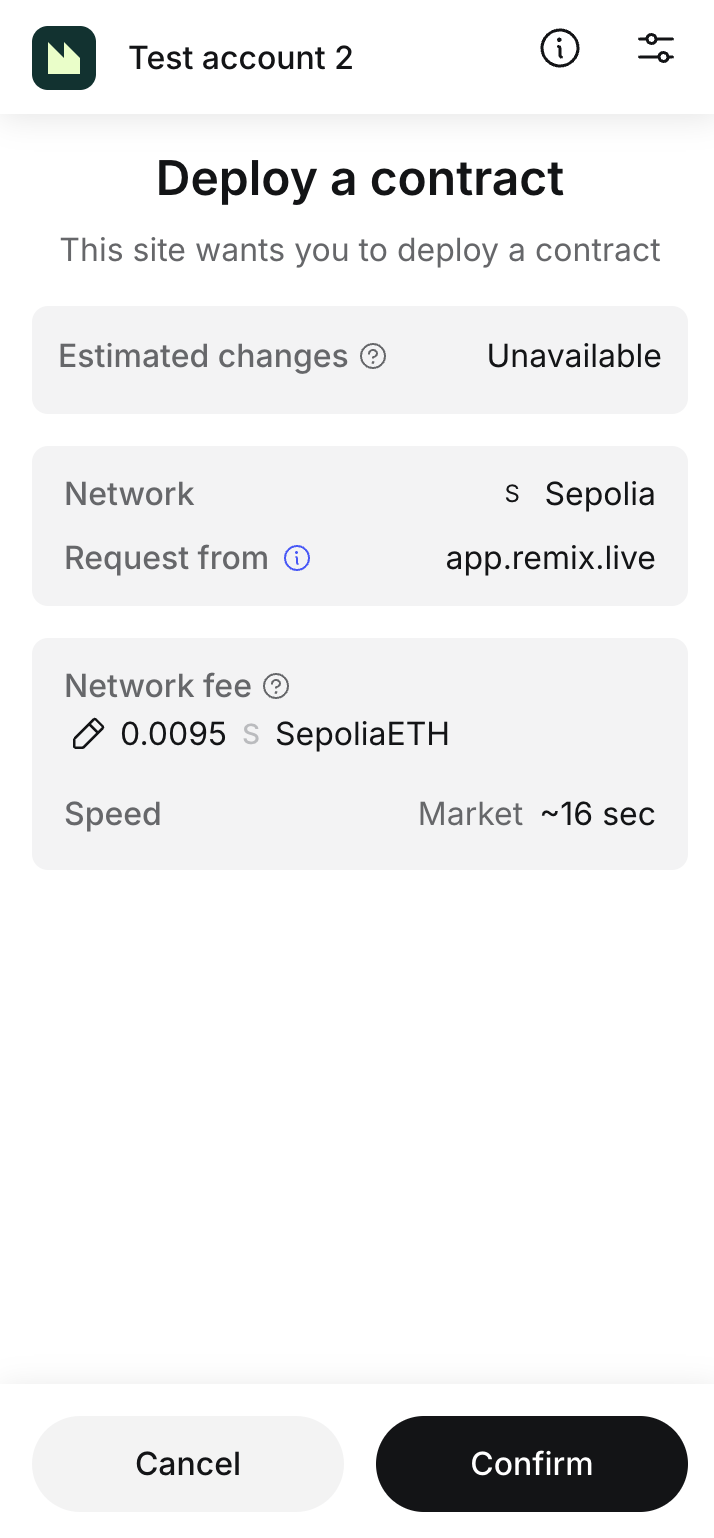 

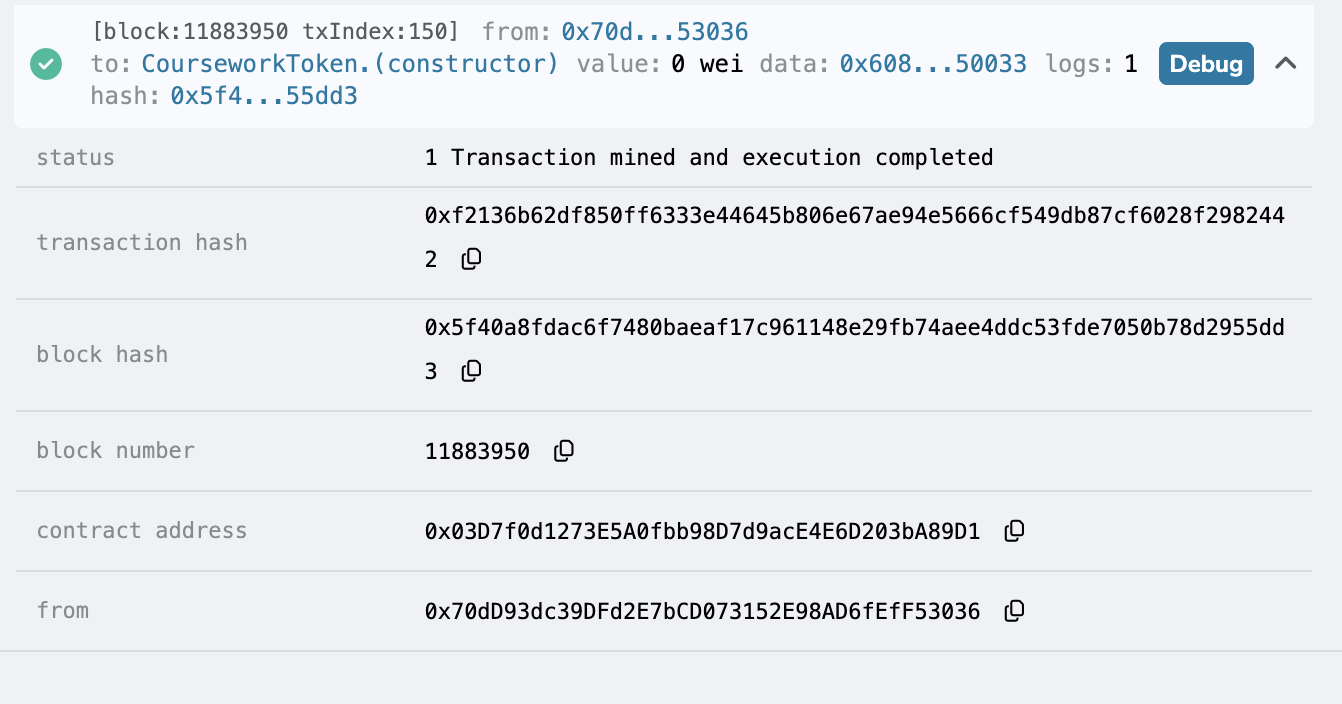 

- Contract name: CourseworkToken
- Symbol: IFT
- Total supply: 100
- Deployer: 0x70dD93dc39DFd2E7bCD073152E98AD6fEfF53036
- Contract address: 0x03D7f0d1273E5A0fbb98D7d9acE4E6D203bA89D1
- Deployment transaction ID: https://sepolia.etherscan.io/tx/0xf2136b62df850ff6333e44645b806e67ae94e5666cf549db87cf6028f2982442
- Transfer transaction ID for sending 10 tokens: https://sepolia.etherscan.io/tx/0x0d41e2227198986d2298c5d105c31bdd4269581f1a27f304a1fb8a1a1887b1b1 